processing data

In [99]:
import os
import cv2
import numpy as np
from sklearn.utils import shuffle
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight

def load_and_preprocess_data(
    data_dir: str, 
    target_size:tuple = (224, 224) 
    ,validation_extension : tuple = ('.jpeg', '.jpg', '.bmp', '.png')
    ):
    images = []
    labels = []
    
    if not os.path.exists(data_dir):
        raise FileNotFoundError(f"The specified data directory '{data_dir}' does not exist.")
    
    class_names = sorted([d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))])
    
    print(f"Found classes: {class_names} , with len : {len(class_names)}")
    
    corruputed_count = 0
    skipped_count = 0
    for label in class_names:
        class_dir = os.path.join(data_dir, label)
        file_list = os.listdir(class_dir)
        
        print(f"Processing class '{label}' with {len(file_list)} files.")
        
        for file_name in file_list:
            img_path = os.path.join(class_dir,file_name)
            ext = os.path.splitext(file_name)[1].lower()
            if ext not in validation_extension:
                try:
                    os.remove(img_path)
                    print(f"Removed file '{img_path}' due to invalid extension '{ext}'.")
                except Exception as e:
                    print(f"Error removing file '{img_path}': {e}")
                skipped_count += 1
                continue
            try:
                img = cv2.imread(img_path)
                
                if img is None:
                    print(f"[CORRUPTED] Could not read image '{img_path}'. Skipping.")
                    corruputed_count += 1
                    os.remove(img_path)
                    continue
                
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, target_size)
                images.append(img)
                labels.append(label)
                
            except Exception as e:
                print(f"[ERROR] An error occurred while processing image '{img_path}': {e}. Skipping.")
                if os.path.exists(img_path):
                    os.remove(img_path)
                skipped_count += 1

    print(f"Preprocessing complete. Corrupted images: {corruputed_count}, Skipped images: {skipped_count}.")
    
    images , labels = shuffle(images, labels, random_state=42)
    images_arr = np.array(images)
    labels_arr = np.array(labels)
    print(f"Final dataset shape: images {images_arr.shape}, labels {labels_arr.shape}")
    return images_arr, labels_arr ,class_names


images_arr, labels_arr, class_names = load_and_preprocess_data("../data/raw")


Found classes: ['glioma', 'meningioma', 'notumor', 'pituitary'] , with len : 4
Processing class 'glioma' with 1621 files.
Processing class 'meningioma' with 1645 files.
Processing class 'notumor' with 2000 files.
Processing class 'pituitary' with 1757 files.
Preprocessing complete. Corrupted images: 0, Skipped images: 0.
Final dataset shape: images (7023, 224, 224, 3), labels (7023,)


Afficher graphiquement le nombre d’images dans chaque classe.

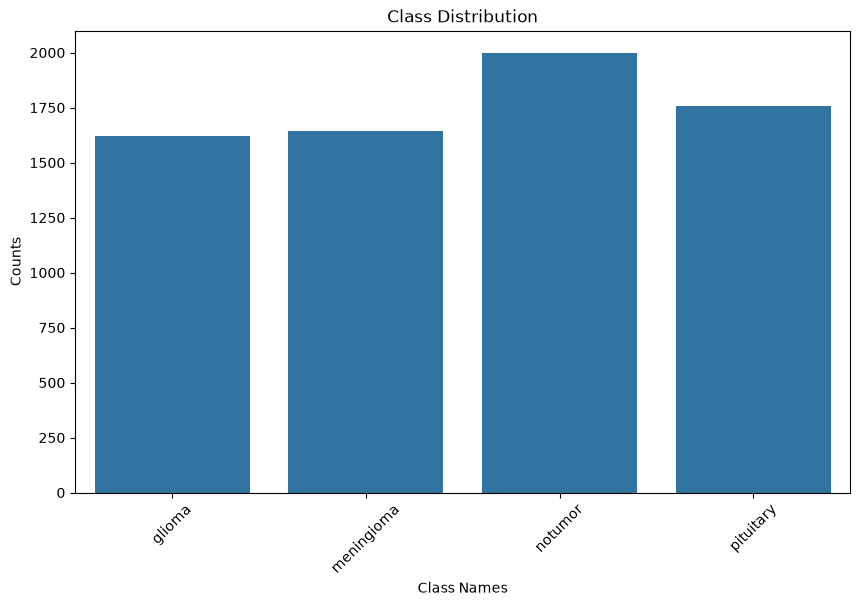

In [100]:
def plot_class_visualization(lavels_arr):
    class_names, counts = np.unique(lavels_arr, return_counts=True)
    plt.figure(figsize=(10, 6))
    sns.barplot(x=class_names, y=counts)
    plt.title("Class Distribution")
    plt.xlabel("Class Names")
    plt.ylabel("Counts")
    plt.xticks(rotation=45)
        
plot_class_visualization(labels_arr)

Montrer un échantillon d’images pour chaque classe.

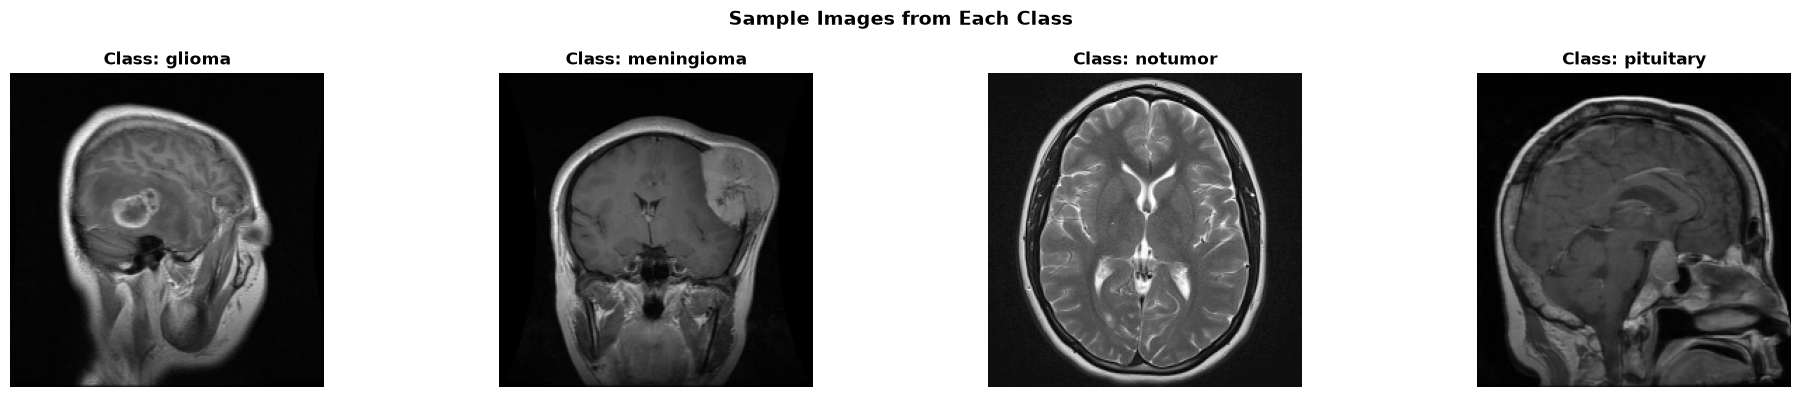

In [101]:
import matplotlib.pyplot as plt
import numpy as np

def display_sample_images(images_arr, labels_arr, class_names):

    fig, axes = plt.subplots(1, 4, figsize=(20, 4))

    for i, cls in enumerate(class_names):
        indices = np.where(labels_arr == cls)[0]

        sample_index = indices[0]
        axes[i].imshow(images_arr[sample_index])
        axes[i].set_title(f"Class: {cls}", fontsize=12, fontweight='bold')
        axes[i].axis('off')

    plt.suptitle("Sample Images from Each Class", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

display_sample_images(images_arr, labels_arr, class_names)

Vérifier l’équilibre entre les classes et appliquer un rééquilibrage si nécessaire.

In [102]:
def check_class_balance(labels_arr):
    classes, counts = np.unique(labels_arr, return_counts=True)
    total_images = len(labels_arr)
    max_count = np.max(counts)
    min_count = np.min(counts)
    imbalance_ratio = max_count / min_count
    for cls, count in zip(classes, counts):
        percentage = (count / total_images) * 100
        print(f"Class '{cls}': {count} images ({percentage:.2f}%)")
    print(f"Imbalance ratio (max/min): {imbalance_ratio:.2f}")
    if imbalance_ratio > 1.5:
        print("Warning: Significant class imbalance detected.")
    else:
        print("Class distribution is relatively balanced.")
    
check_class_balance(labels_arr)

Class 'glioma': 1621 images (23.08%)
Class 'meningioma': 1645 images (23.42%)
Class 'notumor': 2000 images (28.48%)
Class 'pituitary': 1757 images (25.02%)
Imbalance ratio (max/min): 1.23
Class distribution is relatively balanced.


Transformer les étiquettes textuelles en format numérique (ex. avec LabelEncoder ou to_categorical).

In [103]:
from sklearn.preprocessing import LabelEncoder

def encoder_labels(labels_arr):
    le = LabelEncoder()
    encoded_labels = le.fit_transform(labels_arr)
    return encoded_labels, le

encoded_labels, label_encoder = encoder_labels(labels_arr)
print("Encoded labels:", encoded_labels)
print("Label encoder:", label_encoder)

Encoded labels: [2 1 1 ... 2 3 0]
Label encoder: LabelEncoder()


Diviser les données en ensembles d’entraînement et de test.

In [104]:
from sklearn.model_selection import train_test_split
def split_classes(images_arr, y_encoded, test_size=0.2, random_state=42):
    X_train, X_test, y_train, y_test = train_test_split(images_arr, y_encoded, test_size=test_size, random_state=random_state, stratify=y_encoded)
    return X_train, X_test, y_train, y_test
X_train, X_test, y_train, y_test = split_classes(images_arr, encoded_labels)

Normaliser les valeurs des pixels dans la plage [0, 1].

In [105]:


def normalize_pixel_value(X_train, X_test):
    X_train_norm = X_train.astype('float32') / 255.0
    X_test_norm = X_test.astype('float32') / 255.0
    return X_train_norm, X_test_norm

normalized_X_train, normalized_X_test = normalize_pixel_value(X_train, X_test)


Définir l’architecture CNN (Conv2D + MaxPooling + Dropout + Dense) avec des paramètres optimaux.
Choisir les meilleures fonctions d’activation pour les couches cachées et la couche de sortie.

In [106]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_brainscan_cnn():
    model = models.Sequential([
        layers.Input(shape=(224, 224, 3)),
        
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),
        
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),
        
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.50),
        layers.Dense(4, activation='softmax')
    ])
    return model


Compiler le modèle (ex. : Optimiseur Adam, fonction de perte categorical_crossentropy).


In [107]:
from matplotlib.pyplot import plot


model = build_brainscan_cnn()

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)



Utiliser les fonctions model.summary() et plot_model() pour vérifier l’architecture du modèle.

Model: "sequential_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_69 (Conv2D)              │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_69 (MaxPooling2D) │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_70 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_70 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_69 (Dropout)            │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_71 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_71 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_70 (Dropout)            │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_23 (Flatten)            │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_71 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

None


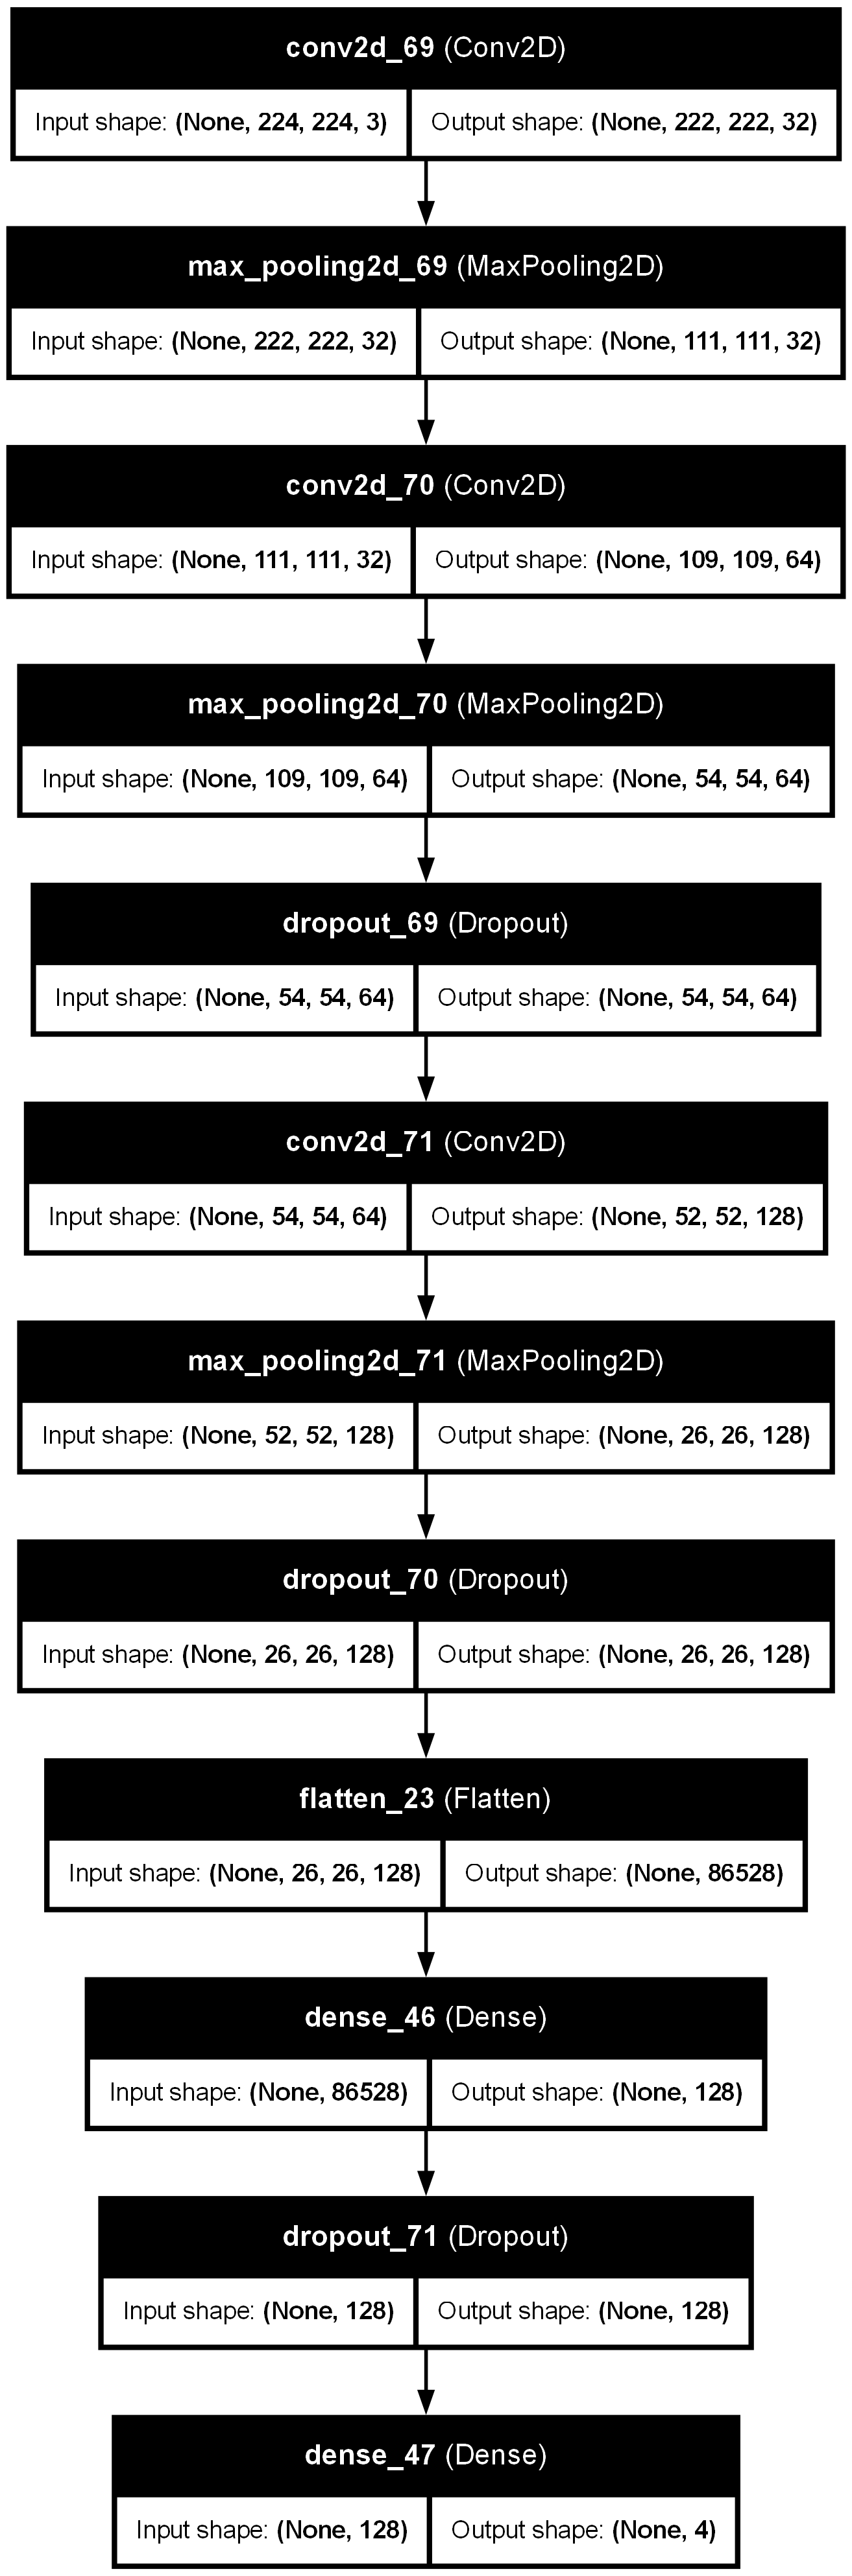

In [108]:
from tensorflow.keras.utils import plot_model
from IPython.display import Image

print(model.summary())

plot_model(
    model, 
    to_file='brainscan_cnn_architecture.png', 
    show_shapes=True, 
    show_layer_names=True
)

Image(filename='brainscan_cnn_architecture.png')

Déterminer les hyperparamètres (taux d’apprentissage, nombre d’époques, taille de batch).

Model compiled successfully.

Starting training...
Epoch 1/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 353ms/step - accuracy: 0.6347 - loss: 0.8804
Epoch 1: val_loss improved from None to 0.52352, saving model to ./brain_tumor_best.h5



Epoch 1: finished saving model to ./brain_tumor_best.h5
176/176 ━━━━━━━━━━━━━━━━━━━━ 71s 384ms/step - accuracy: 0.6347 - loss: 0.8804 - val_accuracy: 0.7972 - val_loss: 0.5235
Epoch 2/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 345ms/step - accuracy: 0.8010 - loss: 0.5211
Epoch 2: val_loss improved from 0.52352 to 0.40683, saving model to ./brain_tumor_best.h5



Epoch 2: finished saving model to ./brain_tumor_best.h5
176/176 ━━━━━━━━━━━━━━━━━━━━ 66s 374ms/step - accuracy: 0.8010 - loss: 0.5211 - val_accuracy: 0.8527 - val_loss: 0.4068
Epoch 3/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 327ms/step - accuracy: 0.8473 - loss: 0.3896
Epoch 3: val_loss improved from 0.40683 to 0.30181, saving model to ./brain_tumor_best.h5



Epoch 3: finished saving model to ./brain_tumor_best.h5
176/176 ━━━━━━━━━━━━━━━━━━━━ 62s 355ms/step - accuracy: 0.8473 - loss: 0.3896 - val_accuracy: 0.8854 - val_loss: 0.3018
Epoch 4/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 342ms/step - accuracy: 0.8804 - loss: 0.3031
Epoch 4: val_loss improved from 0.30181 to 0.24911, saving model to ./brain_tumor_best.h5



Epoch 4: finished saving model to ./brain_tumor_best.h5
176/176 ━━━━━━━━━━━━━━━━━━━━ 65s 367ms/step - accuracy: 0.8804 - loss: 0.3031 - val_accuracy: 0.9011 - val_loss: 0.2491
Epoch 5/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 0s 340ms/step - accuracy: 0.9035 - loss: 0.2439
Epoch 5: val_loss improved from 0.24911 to 0.22594, saving model to ./brain_tumor_best.h5


...

 Total params: 33,508,430 (127.82 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 22,338,954 (85.22 MB)

None
Training history: {'accuracy': [0.6347454786300659, 0.8009967803955078, 0.8472766280174255, 0.8803845047950745, 0.9035243988037109, 0.9238163232803345, 0.935208261013031, 0.9419722557067871, 0.9505162239074707, 0.9579921960830688, 0.9660021066665649, 0.9642221331596375], 'loss': [0.8804014325141907, 0.52108234167099, 0.38963809609413147, 0.30306607484817505, 0.24388141930103302, 0.19469542801380157, 0.16434910893440247, 0.14733079075813293, 0.12369000166654587, 0.10167257487773895, 0.09229476004838943, 0.08891752362251282], 'val_accuracy': [0.7971529960632324, 0.8526690602302551, 0.8854092359542847, 0.9010676145553589, 0.9202846884727478, 0.935943067073822, 0.9345195889472961, 0.9409252405166626, 0.9466192126274109, 0.9473309516906738, 0.9466192126274109, 0.945907473564148], 'val_loss': [0.5235183238983154, 0.4068306088447571, 0.30181312561035156, 0.2491072565317154, 0.22594375908374786, 0.18557365238666534, 0.21060138940811157, 0.18688422441482544, 0.19580553472042084, 0.18779094

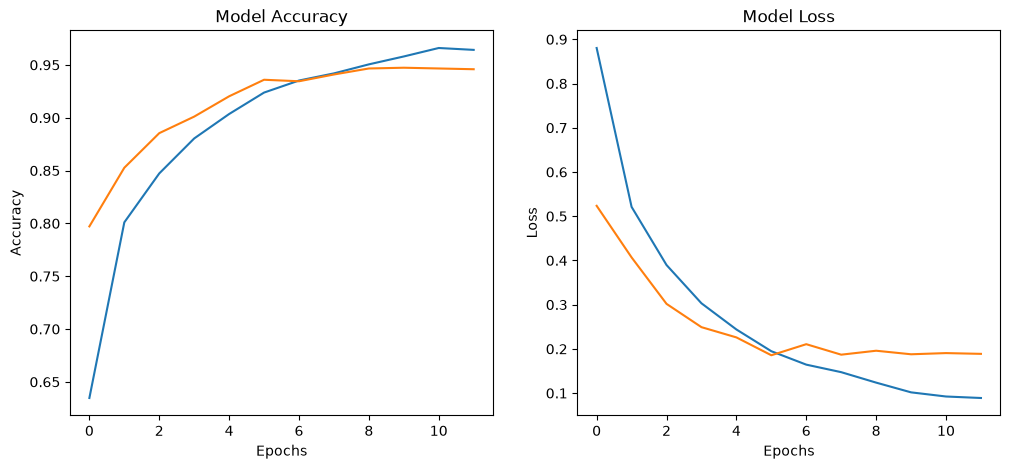

In [109]:

import time 
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping ,ModelCheckpoint

def adjust_hyperparameters(X_train, y_train, X_test, y_test, learning_rate=0.001, EPOCHS=20 , batch_size=32 , callbacks=None):
    model = build_brainscan_cnn()
    
    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    
    model.compile(
        optimizer=optimizer, 
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    print("Model compiled successfully.")
    
    print("\nStarting training...")
    start_time = time.time()
    
    history = model.fit(
        x=X_train, 
        y=y_train,
        epochs=EPOCHS, 
        callbacks=callbacks,
        batch_size=batch_size,
        validation_data=(X_test, y_test)
    )
    
    end_time = time.time()
    total_seconds = end_time - start_time
    print(f"\nTraining completed in {total_seconds:.2f} seconds.")
    
    return model, history

early_stopping = EarlyStopping(
    monitor='val_loss', 
    patience=6, 
    restore_best_weights=True
)

checkpoint_callback = ModelCheckpoint(
    filepath="./brain_tumor_best.h5",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

model, history = adjust_hyperparameters(
    X_train=normalized_X_train, 
    y_train=y_train, 
    X_test=normalized_X_test, 
    y_test=y_test,
    callbacks=[early_stopping, checkpoint_callback]
)

print("Model training completed successfully.")
print(model.summary())
print("Training history:", history.history)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.show()



Générer une matrice de confusion et un rapport de classification.

44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 92ms/step


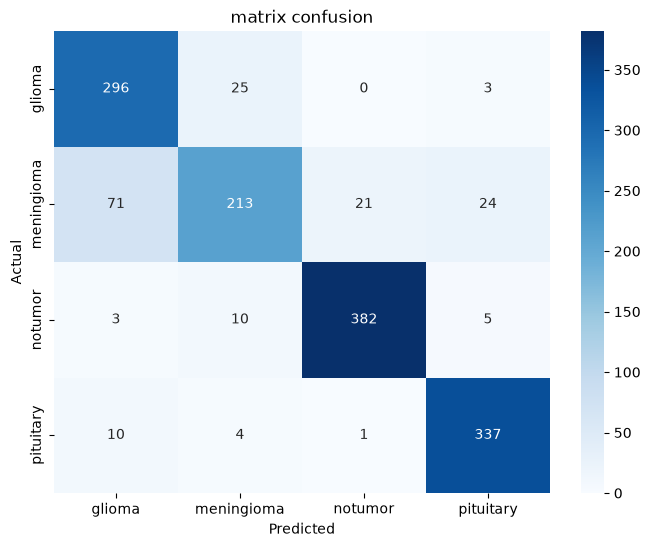

Classification Report:
               precision    recall  f1-score   support

      glioma       0.78      0.91      0.84       324
  meningioma       0.85      0.65      0.73       329
     notumor       0.95      0.95      0.95       400
   pituitary       0.91      0.96      0.93       352

    accuracy                           0.87      1405
   macro avg       0.87      0.87      0.86      1405
weighted avg       0.88      0.87      0.87      1405



In [110]:
from sklearn.metrics import confusion_matrix,classification_report
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt
class_names = label_encoder.classes_
best_model = tf.keras.models.load_model("brain_tumor_detector.h5")

y_prob = best_model.predict(normalized_X_test)

y_true = np.argmax(to_categorical(y_test, num_classes=len(class_names)), axis=1)
y_pred = np.argmax(y_prob, axis=1)
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title("matrix confusion")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()
print("Classification Report:\n", classification_report(y_true, y_pred, target_names=class_names))

Afficher des exemples de prédictions correctes et incorrectes.

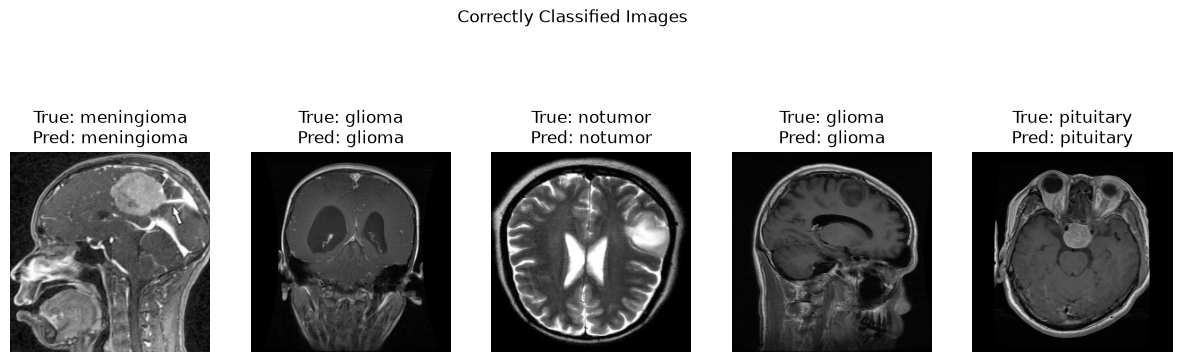

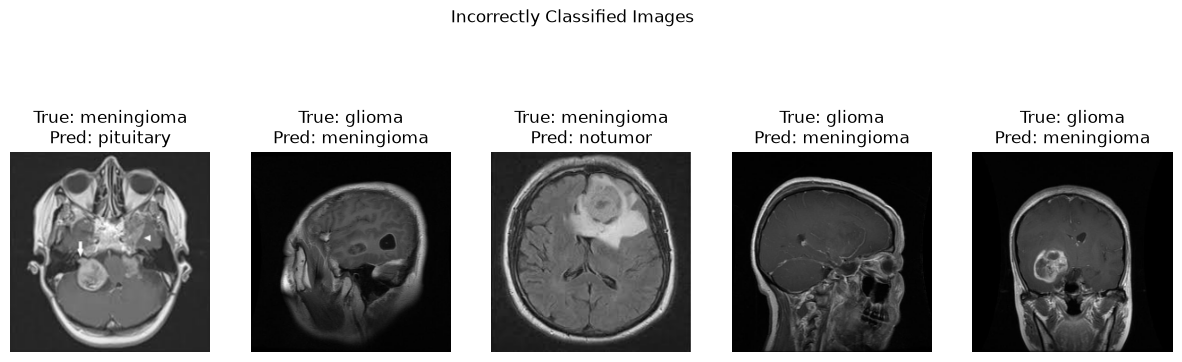

In [111]:


def show_prediction_image(indices,title,y_true, y_pred, normalized_X_test, class_names):

    plt.figure(figsize=(15, 5))
    for i, idx in enumerate(indices[:5]):
        plt.subplot(1, 5, i + 1)
        plt.imshow(normalized_X_test[idx])
        plt.title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}")
        plt.axis('off')
    plt.suptitle(title)
    plt.show()
    
correct_indeces = np.where(y_true == y_pred)[0]
incorrect_indeces = np.where(y_true != y_pred)[0]
    
show_prediction_image(correct_indeces,"Correctly Classified Images",y_true, y_pred, normalized_X_test, class_names)
show_prediction_image(incorrect_indeces,"Incorrectly Classified Images",y_true, y_pred, normalized_X_test, class_names)



Créer une fonction predict_image(path) pour tester une image.

In [117]:


def predict_image(path):
    img = cv2.imread(path)

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)      
    img = cv2.resize(img, (224, 224))               
    img = img.astype('float32') / 255.0             
    img = np.expand_dims(img, axis=0)      

    model = tf.keras.models.load_model("brain_tumor_detector.h5")
    predictions = model.predict(img)
    print(f"Predictions: {predictions}")
    

    predicted_index = np.argmax(predictions[0])
    print(f"Predicted probabilities: {predicted_index}")
    class_names = ['glioma', 'meningioma', 'notumor', 'pituitary']
    predicted_label = class_names[predicted_index]
    confidence = np.max(predictions[0]) * 100
    
    print(f"Diagnostic : {predicted_label} ({confidence:.2f}%)")
    return predicted_label, confidence

predict_image("../data/raw/glioma/Te-gl_0010.jpg")

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predictions: [[0.9537033  0.04100244 0.00190284 0.00339146]]
Predicted probabilities: 0
Diagnostic : glioma (95.37%)


('glioma', np.float32(95.37033))

NameError: name 'predictions' is not defined